In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

RUTA_DIAGNOSTICOS = "Diagnostics.xlsx"  

In [2]:
%pip install openpyxl scipy matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---
## Punto 2. Análisis estadístico de *Diagnostics.xlsx*

**Qué se hace:**
1. Se carga el archivo y se revisa qué contiene.
2. Se responde cada pregunta con tablas, gráficas y una prueba estadística sencilla:
   - **chi-cuadrado** para el género;
   - **Kruskal-Wallis** para la edad.
3. Se escoge el subconjunto de datos para los siguientes puntos.

### 2.0 Carga y descripción general

In [3]:
df = pd.read_excel(RUTA_DIAGNOSTICOS)

print("Número de registros y columnas:", df.shape)
print("Valores faltantes:", df.isna().sum().sum())
df.head()

Número de registros y columnas: (10646, 16)
Valores faltantes: 0


,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


In [4]:
# Significado de las abreviaturas de los ritmos
nombres = {
    "SB": "Bradicardia sinusal",
    "SR": "Ritmo sinusal",
    "AFIB": "Fibrilación auricular",
    "ST": "Taquicardia sinusal",
    "SVT": "Taquicardia supraventricular",
    "AF": "Flutter auricular",
    "SA": "Irregularidad sinusal",
    "AT": "Taquicardia auricular",
    "AVNRT": "Taquicardia por reentrada nodal AV",
    "AVRT": "Taquicardia por reentrada AV",
    "SAAWR": "Marcapasos auricular migratorio",
}

# Estadística descriptiva de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
PatientAge,10646.0,59.186831,18.030019,4.0,49.0,62.0,72.0,98.0
VentricularRate,10646.0,84.136107,34.455349,34.0,57.0,73.0,104.0,263.0
AtrialRate,10646.0,92.577870,60.093940,0.0,57.0,72.0,106.0,535.0
QRSDuration,10646.0,90.989292,17.479540,18.0,80.0,88.0,98.0,256.0
QTInterval,10646.0,384.150855,59.226289,114.0,344.0,390.0,426.0,736.0
QTCorrected,10646.0,434.154048,39.354182,219.0,408.0,430.0,456.0,760.0
RAxis,10646.0,39.620609,41.212648,-89.0,14.0,46.0,68.0,270.0
TAxis,10646.0,44.637704,57.478092,-89.0,19.0,42.0,62.0,270.0
QRSCount,10646.0,13.839470,5.676339,5.0,9.0,12.0,17.0,40.0
QOnset,10646.0,219.260567,6.410413,159.0,216.0,219.0,224.0,240.0


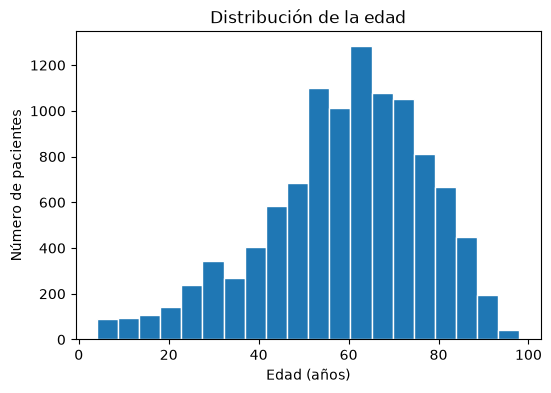

Gender
MALE      5956
FEMALE    4690
Name: count, dtype: int64
Porcentaje de hombres: 55.9 %


In [5]:
def graficar_barras(etiquetas, valores, titulo, etiqueta_y):
    """Gráfica de barras con el valor escrito encima de cada barra."""
    plt.figure(figsize=(10, 4))
    plt.bar(etiquetas, valores)
    for i in range(len(valores)):
        plt.text(i, valores[i], f"{valores[i]:.1f}", ha="center", va="bottom", fontsize=9)
    plt.title(titulo)
    plt.ylabel(etiqueta_y)
    plt.show()


plt.figure(figsize=(6, 4))
plt.hist(df["PatientAge"], bins=20, edgecolor="white")
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de pacientes")
plt.show()

genero = df["Gender"].value_counts()
print(genero)
print("Porcentaje de hombres:", round(100 * genero["MALE"] / len(df), 1), "%")

**Descripción general.**
- La base tiene **10.646 pacientes** y **16 variables**, sin valores faltantes.
- Las variables principales son:
  - `Rhythm`: el ritmo, con 11 clases;
  - `Beat`: condiciones adicionales;
  - `PatientAge` y `Gender`: datos del paciente;
  - mediciones del ECG: frecuencias, QRS, QT, ejes.
- La edad va de 4 a 98 años, con mediana de 62.
- El 55,9 % de los pacientes son hombres y el 44,1 % mujeres.


### 2.1 ¿Qué tipo de arritmias son más prevalentes?

           n      %                              Nombre
Rhythm                                                 
SB      3889  36.53                 Bradicardia sinusal
SR      1826  17.15                       Ritmo sinusal
AFIB    1780  16.72               Fibrilación auricular
ST      1568  14.73                 Taquicardia sinusal
SVT      587   5.51        Taquicardia supraventricular
AF       445   4.18                   Flutter auricular
SA       399   3.75               Irregularidad sinusal
AT       121   1.14               Taquicardia auricular
AVNRT     16   0.15  Taquicardia por reentrada nodal AV
AVRT       8   0.08        Taquicardia por reentrada AV
SAAWR      7   0.07     Marcapasos auricular migratorio


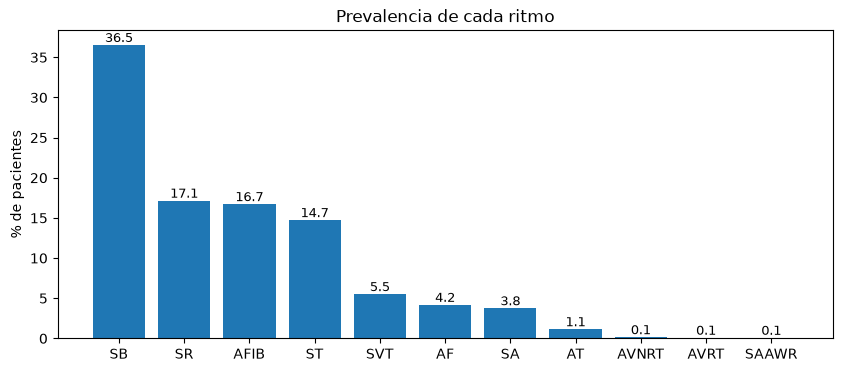

In [6]:
def prevalencia(df):
    """Número de pacientes y porcentaje de cada ritmo."""
    conteo = df["Rhythm"].value_counts()
    porcentaje = 100 * conteo / len(df)
    tabla = pd.DataFrame({"n": conteo, "%": porcentaje.round(2)})
    tabla["Nombre"] = [nombres[r] for r in tabla.index]
    return tabla


tabla_prev = prevalencia(df)
print(tabla_prev)
graficar_barras(tabla_prev.index, tabla_prev["%"].values, "Prevalencia de cada ritmo", "% de pacientes")

**Respuesta.**
- La arritmia más frecuente es la **bradicardia sinusal (SB, 36,5 %)**.
- Le siguen el ritmo sinusal normal (SR, 17,2 %), la **fibrilación auricular (AFIB, 16,7 %)** y la **taquicardia sinusal (ST, 14,7 %)**.
- Los ritmos AVNRT, AVRT y SAAWR tienen menos de 20 pacientes cada uno. Es decir, la base está **desbalanceada**.


### 2.2 ¿Hay arritmias más prevalentes para un género específico?
Para cada ritmo se compara el **% de hombres** con el % de hombres de toda la base (55,9 %). Luego se aplica una **prueba chi-cuadrado** entre ese ritmo y el resto de la base:
- si **p < 0,05**, la diferencia de género en ese ritmo es estadísticamente significativa.

Solo se prueban los ritmos con 30 pacientes o más, porque con muy pocos datos la prueba chi-cuadrado no es confiable.


In [7]:
def prueba_genero(df, ritmo):
    """Chi-cuadrado de una tabla 2x2: (este ritmo vs el resto) x (hombres vs mujeres)."""
    es_ritmo = df["Rhythm"] == ritmo
    tabla = pd.crosstab(es_ritmo, df["Gender"])
    chi2, p, gl, esperados = stats.chi2_contingency(tabla)
    return p


pct_hombres_total = 100 * (df["Gender"] == "MALE").mean()
filas = []
for ritmo in tabla_prev.index:
    datos_ritmo = df[df["Rhythm"] == ritmo]
    pct_hombres = 100 * (datos_ritmo["Gender"] == "MALE").mean()
    if len(datos_ritmo) >= 30:
        p = prueba_genero(df, ritmo)
    else:
        p = np.nan                      # muy pocos datos para la prueba
    filas.append([ritmo, len(datos_ritmo), round(pct_hombres, 1), round(100 - pct_hombres, 1), p])

tabla_genero = pd.DataFrame(filas, columns=["Ritmo", "n", "% hombres", "% mujeres", "p-valor"])
print(f"% de hombres en toda la base: {pct_hombres_total:.1f} %")
tabla_genero

% de hombres en toda la base: 55.9 %


,Ritmo,n,% hombres,% mujeres,p-valor
0,SB,3889,63.8,36.2,4.511473e-35
1,SR,1826,43.9,56.1,7.820535e-30
2,AFIB,1780,58.5,41.5,1.945825e-02
3,ST,1568,51.0,49.0,1.852296e-05
4,SVT,587,47.5,52.5,2.881532e-05
5,AF,445,57.8,42.2,4.619862e-01
6,SA,399,55.9,44.1,1.000000e+00
7,AT,121,52.9,47.1,5.563121e-01
8,AVNRT,16,25.0,75.0,NaN
9,AVRT,8,62.5,37.5,NaN


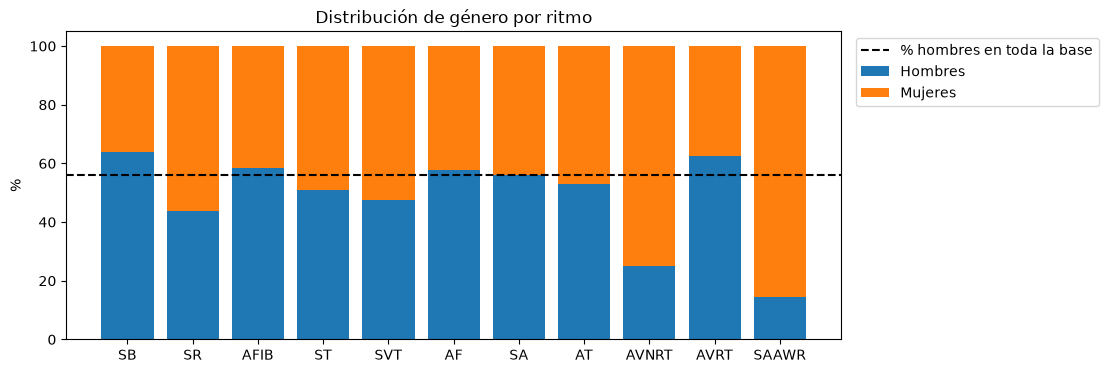

In [8]:
plt.figure(figsize=(10, 4))
plt.bar(tabla_genero["Ritmo"], tabla_genero["% hombres"], label="Hombres")
plt.bar(tabla_genero["Ritmo"], tabla_genero["% mujeres"], bottom=tabla_genero["% hombres"], label="Mujeres")
plt.axhline(pct_hombres_total, color="black", linestyle="--", label="% hombres en toda la base")
plt.title("Distribución de género por ritmo")
plt.ylabel("%")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

**Respuesta.** Sí hay ritmos con predominio de un género, con p < 0,05 en todos estos casos:
- **Más frecuentes en hombres:**
  - bradicardia sinusal (SB, 63,8 % hombres);
  - fibrilación auricular (AFIB, 58,5 % hombres). En este caso la diferencia es pequeña (p ≈ 0,02).
- **Más frecuentes en mujeres:**
  - taquicardia sinusal (ST);
  - taquicardia supraventricular (SVT, 52,5 % mujeres);
  - ritmo sinusal normal (SR, 56 % mujeres).
- **Sin diferencia significativa:** flutter (AF), irregularidad sinusal (SA) y taquicardia auricular (AT).
- AVNRT (75 % mujeres) y SAAWR (86 % mujeres) también parecen ser más frecuentes en mujeres, pero tienen muy pocos casos para probarlo.


### 2.3 ¿Hay arritmias más prevalentes para una edad?
Primero se mira la edad en cada ritmo. Luego se divide a los pacientes en grupos de edad por décadas y se busca el ritmo más frecuente en cada grupo.


        count  mean  median  min  max
Rhythm                               
SA        399  34.7    29.0    4   93
SAAWR       7  51.1    49.0   15   87
SR       1826  54.4    55.0    4   95
SVT       587  55.6    56.0    4   96
ST       1568  54.6    57.0    4   96
AVNRT      16  57.9    59.0   27   84
SB       3889  58.3    60.0   10   98
AVRT        8  57.5    62.5   25   77
AT        121  65.7    71.0    8   94
AF        445  71.1    72.0   21   97
AFIB     1780  73.4    75.0   30   98


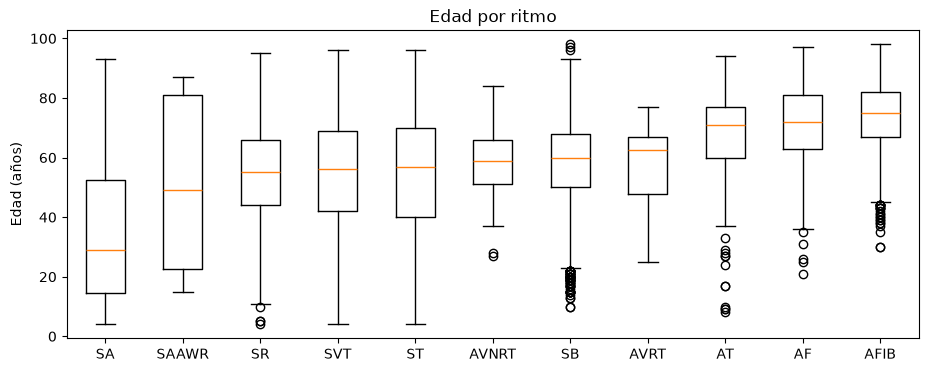

Kruskal-Wallis: H = 2221.3, p = 0


In [9]:
def resumen_edad(df):
    """Edad media, mediana, mínima y máxima de cada ritmo, ordenada por la mediana."""
    tabla = df.groupby("Rhythm")["PatientAge"].agg(["count", "mean", "median", "min", "max"])
    return tabla.sort_values("median").round(1)


tabla_edad = resumen_edad(df)
print(tabla_edad)

# Diagrama de cajas: una caja por ritmo
edades = [df[df["Rhythm"] == r]["PatientAge"] for r in tabla_edad.index]
plt.figure(figsize=(11, 4))
plt.boxplot(edades)
plt.xticks(range(1, len(tabla_edad) + 1), tabla_edad.index)
plt.title("Edad por ritmo")
plt.ylabel("Edad (años)")
plt.show()

# Prueba de Kruskal-Wallis: ¿la edad es distinta entre los ritmos?
H, p = stats.kruskal(*edades)
print(f"Kruskal-Wallis: H = {H:.1f}, p = {p:.3g}")

In [10]:
def grupo_de_edad(edad):
    """Devuelve la década a la que pertenece una edad."""
    if edad < 20:
        return "<20"
    elif edad >= 90:
        return "90+"
    else:
        inicio = (edad // 10) * 10
        return f"{inicio}-{inicio + 9}"


df["GrupoEdad"] = df["PatientAge"].apply(grupo_de_edad)
tabla_grupos = pd.crosstab(df["GrupoEdad"], df["Rhythm"])
orden_grupos = ["<20", "20-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80-89", "90+"]
tabla_grupos = tabla_grupos.loc[orden_grupos, tabla_prev.index]   # filas por edad, columnas por prevalencia
print("Número de pacientes por grupo de edad y ritmo:")
print(tabla_grupos)

print("\nRitmo más frecuente en cada grupo de edad:")
for grupo in tabla_grupos.index:
    fila = tabla_grupos.loc[grupo]
    print(f"  {grupo:6s} -> {fila.idxmax():5s} ({100 * fila.max() / fila.sum():.0f} % del grupo)")

Número de pacientes por grupo de edad y ritmo:
Rhythm       SB   SR  AFIB   ST  SVT   AF   SA  AT  AVNRT  AVRT  SAAWR
GrupoEdad                                                             
<20          30   30     0  102   11    0  136   6      0     0      2
20-29       122  117     0  134   44    3   64   5      2     1      1
30-39       231  205     8  139   62    4   50   2      1     0      0
40-49       519  304    52  196  109   26   41   5      0     2      1
50-59      1009  430   140  264  111   44   30  10      5     0      0
60-69      1206  409   395  319  115  104   36  26      5     3      0
70-79       564  231   575  218   63  136   29  44      0     2      1
80-89       195   93   538  177   56   96   11  16      3     0      2
90+          13    7    72   19   16   32    2   7      0     0      0

Ritmo más frecuente en cada grupo de edad:
  <20    -> SA    (43 % del grupo)
  20-29  -> ST    (27 % del grupo)
  30-39  -> SB    (33 % del grupo)
  40-49  -> SB    (41 %

**Respuesta.** Sí: la edad cambia mucho según el ritmo (Kruskal-Wallis, p < 0,001).
- **Irregularidad sinusal (SA):** es de pacientes jóvenes (mediana de 29 años) y es el ritmo más frecuente en menores de 20 años.
- **Taquicardia sinusal (ST):** es la más frecuente entre los 20 y 29 años.
- **Bradicardia sinusal (SB):** domina entre los 30 y 69 años.
- **Fibrilación auricular (AFIB) y flutter (AF):** son de pacientes mayores (medianas de 75 y 72 años). Desde los 70 años la AFIB es el ritmo más frecuente; entre los 80 y 89 años llega al 45 % de los pacientes.


### 2.4 ¿Qué rango de edades y arritmias usar para entrenar algoritmos?
Un algoritmo aprende mejor si cada clase tiene **muchos ejemplos** y si las clases son **comparables**, por ejemplo en edades parecidas.

**Regla usada:** se incluye un ritmo si tiene **al menos 50 pacientes en cada década** entre los 40 y los 89 años.


In [11]:
def ritmos_suficientes(tabla_grupos, decadas, minimo=50):
    """Ritmos que tienen al menos 'minimo' pacientes en cada una de las décadas indicadas."""
    seleccion = []
    for ritmo in tabla_grupos.columns:
        if (tabla_grupos.loc[decadas, ritmo] >= minimo).all():
            seleccion.append(ritmo)
    return seleccion


decadas = ["40-49", "50-59", "60-69", "70-79", "80-89"]
print(tabla_grupos.loc[decadas])
ritmos_sel = ritmos_suficientes(tabla_grupos, decadas)
print("\nRitmos seleccionados:", ritmos_sel)

Rhythm       SB   SR  AFIB   ST  SVT   AF  SA  AT  AVNRT  AVRT  SAAWR
GrupoEdad                                                            
40-49       519  304    52  196  109   26  41   5      0     2      1
50-59      1009  430   140  264  111   44  30  10      5     0      0
60-69      1206  409   395  319  115  104  36  26      5     3      0
70-79       564  231   575  218   63  136  29  44      0     2      1
80-89       195   93   538  177   56   96  11  16      3     0      2

Ritmos seleccionados: ['SB', 'SR', 'AFIB', 'ST', 'SVT']


In [12]:
# Subconjunto: ritmos seleccionados y edades entre 40 y 89 años
sub = df[df["Rhythm"].isin(ritmos_sel) & (df["PatientAge"] >= 40) & (df["PatientAge"] <= 89)]

print("Pacientes en el subconjunto:", len(sub))
print(sub["Rhythm"].value_counts())
print("\nEdad media por ritmo:")
print(sub.groupby("Rhythm")["PatientAge"].mean().round(1))

# Se guarda para el punto 3 (compañero) y los puntos siguientes
sub.to_csv("subconjunto_punto2.csv", index=False)

Pacientes en el subconjunto: 8288
Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64

Edad media por ritmo:
Rhythm
AFIB    72.8
SB      61.3
SR      60.1
ST      63.6
SVT     61.2
Name: PatientAge, dtype: float64


**Respuesta.**
- **Rango de edad: 40 a 89 años.** Por debajo de 40 años casi no hay AFIB, y por encima de 90 hay muy pocos pacientes.
- **Ritmos: SB, SR, AFIB, ST y SVT.** Son los únicos que cumplen la regla.
- **Ritmos que quedan fuera:**
  - AF tiene solo 26 pacientes entre 40 y 49 años;
  - SA es casi solo de jóvenes;
  - AT, AVNRT, AVRT y SAAWR tienen muy pocos pacientes.
- El subconjunto tiene **8.288 pacientes** y se guarda en `subconjunto_punto2.csv`. Este archivo lo usa el punto 3.


### 2.5 ¿Coinciden la literatura y la base de datos?

| Base de datos | Literatura | ¿Coincide? |
|---|---|---|
| SB es el ritmo más frecuente, seguido de SR, AFIB y ST | Zheng *et al.* (2020), con la versión grande de esta misma base, encuentra el mismo orden: SB 38,6 %, SR 18,1 %, AFIB 17,5 %, ST 15,4 % | Sí |
| La AFIB aumenta con la edad (mediana de 75 años) | La fibrilación auricular pasa de 0,1 % en menores de 49 años a 13–18 % en mayores de 80 [Kavousi 2020]. Gadaleta *et al.* (2023) reporta 2,2 % en menores de 65 y 6,5 % en mayores de 65 | Sí |
| La AFIB tiene más hombres (58,5 %) | La fibrilación auricular es más frecuente en hombres [Kavousi 2020; Bernal y Moro 2006] | Sí |
| La SVT y la AVNRT tienen más mujeres | La AVNRT es cerca de 2 veces más frecuente en mujeres [Bernal y Moro 2006] | Sí |
| La SB tiene más hombres | Los hombres tienen menor frecuencia cardiaca en reposo [Bernal y Moro 2006] | Sí |
| La SA aparece sobre todo en jóvenes | Zheng *et al.* (2020) reporta una edad media de 37 años para la irregularidad sinusal, la menor de todos los ritmos | Sí |

**Conclusión.** En general **sí coinciden**. La diferencia está en el ritmo más frecuente: en la población general la arritmia sostenida más común es la fibrilación auricular, pero esta base viene de pacientes de dos hospitales, no de toda la población.

*Referencias:* Kavousi M. (2020) *Front. Cardiovasc. Med.* 7:3; Bernal O., Moro C. (2006) *Rev. Esp. Cardiol.* 59(6):609-618; Zheng J. *et al.* (2020) *Sci. Rep.* 10:2898; Gadaleta M. *et al.* (2023) *npj Digit. Med.* 6:229.


### 2.6 ¿Qué otros análisis se proponen?
1. **Analizar la columna `Beat`.** El 49 % de los pacientes tiene condiciones adicionales, como bloqueos de rama o extrasístoles. Zheng *et al.* mostraron que estas condiciones empeoran la clasificación.
2. **Comparar las mediciones del ECG entre ritmos.** Por ejemplo, la frecuencia ventricular, el QRS y el QTc, para verificar que las etiquetas sean coherentes; la SB debería tener una frecuencia menor de 60 lpm.
3. **Comparar el QTc entre hombres y mujeres.**
4. **Estudiar la edad y el género juntos.** Por ejemplo, ver si el predominio de hombres en la AFIB se mantiene en todas las edades.
5. **Agrupar los ritmos en 4 clases** (SB, AFIB, taquicardias supraventriculares y SR), como hace Zheng *et al.*, para reducir el desbalance.


# Punto 3: fórmulas 1 a 4 de Kotriwar et al. (2018) y biespectro

Referencia: Kotriwar, Kachhara, Harikrishnan y Ambika, *Higher order spectral analysis of ECG signals*, arXiv:1809.08451.

Las cuatro fórmulas del artículo son:

1. Desviación por *detrending* polinomial, $\delta(n)$, para escoger el grado del polinomio.
2. Compresión (normalización min-máx) de la señal a $[0, 1]$.
3. Biespectro $b(f_1, f_2)$ promediado sobre $N$ segmentos.
4. Bicoherencia $B(f_1, f_2)$, el biespectro normalizado entre 0 y 1.

Se trabaja sobre la derivación II de los registros de `ECGDataDenoised` que están en el subconjunto del punto 2.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal

FS = 500                                   # Hz, Chapman-Shaoxing (10 s -> 5000 muestras)
RUTA_SENALES = Path("ECGDataDenoised")     # carpeta con los .csv de las señales (ajustar)
RUTA_SUBCONJUNTO = Path("subconjunto_punto2.csv")
DERIVACION_II = 1                          # columnas: I, II, III, aVR, aVL, aVF, V1..V6

In [14]:
def cargar_ecg(ruta_csv, derivacion=DERIVACION_II):
    # Siempre devuelve un vector 1-D (evita arrastrar formas viejas entre celdas)
    try:
        datos = pd.read_csv(ruta_csv, header=None).to_numpy(dtype=float)
    except ValueError:                     # por si el archivo trae encabezado
        datos = pd.read_csv(ruta_csv).to_numpy(dtype=float)
    x = np.asarray(datos[:, derivacion], dtype=float).ravel()
    if not np.all(np.isfinite(x)) or np.ptp(x) == 0:
        raise ValueError(f"Señal vacía, constante o con NaN: {ruta_csv}")
    return x

## Fórmula 1 — desviación por *detrending* polinomial

Se ajusta un polinomio de grado $n$ a la señal original $x^{(0)}$ y se resta, obteniendo la señal sin tendencia $x^{(n)}$. La desviación entre ambas es

$$\delta(n) = \frac{1}{k}\sum_{i=1}^{k}\left(x^{(0)}(i) - x^{(n)}(i)\right)^2$$

donde $k$ es la longitud de la señal. Se calcula para varios grados y se escoge el grado a partir del cual $\delta(n)$ se satura (los autores encontraron $n = 20$ en registros de 60 s).

**Cuidado al trasladarlo a Chapman.** Los registros duran 10 s, no 60 s. Un polinomio de grado alto en una ventana corta ya no solo sigue la deriva lenta: empieza a seguir la propia frecuencia cardíaca. Se comprobó con senoidales puras de 10 s a 500 Hz:

| Frecuencia | Grado 5 | Grado 10 | Grado 20 |
|---|---|---|---|
| 0.3 Hz (deriva) | 18 % | 97 % | 100 % |
| 0.5 Hz | 11 % | 30 % | 100 % |
| 1.0 Hz (pulso) | 4 % | 5 % | 27 % |
| 1.2 Hz | 3 % | 4 % | 14 % |

Esto es potencia eliminada por el ajuste. Con grado 20 se pierde más de una cuarta parte de la componente de 1 Hz, justo la frecuencia de pulso que se busca en el punto 4. Por eso aquí la curva $\delta(n)$ se usa para elegir el grado, pero con un tope de 10. Además, las señales de `ECGDataDenoised` ya pasaron por un LOESS que quitó la línea base, así que se espera una curva casi plana.

`np.polynomial.Polynomial.fit` reescala el eje temporal internamente; `np.polyfit` con grados altos sobre 5000 puntos es numéricamente inestable.

In [15]:
def detrend_polinomial(x, n):
    # Devuelve (señal sin tendencia, tendencia ajustada)
    t = np.arange(len(x))
    tendencia = np.polynomial.Polynomial.fit(t, x, deg=n)(t)
    return x - tendencia, tendencia


def delta_n(x, n):
    # Ec. (1): delta(n) = (1/k) * sum (x0(i) - xn(i))^2
    xn, _ = detrend_polinomial(x, n)
    return np.mean((x - xn) ** 2)


def curva_delta(x, grados=range(0, 21)):
    grados = np.array(list(grados))
    return grados, np.array([delta_n(x, n) for n in grados])


def elegir_grado(grados, deltas, tol=0.01, grado_max=10):
    # Primer grado en el que delta(n) cambia menos de tol (relativo) respecto al anterior, con tope
    cambio = np.abs(np.diff(deltas)) / np.maximum(deltas[1:], np.finfo(float).eps)
    estables = np.where(cambio < tol)[0]
    g = grados[estables[0] + 1] if len(estables) else grados[-1]
    return int(min(g, grado_max))

## Fórmula 2 — compresión

$$s(t_k) = \frac{x(t_k) - x_{\min}}{x_{\max} - x_{\min}}$$

Lleva todas las señales al intervalo $[0, 1]$ para compararlas sin sesgo por amplitud. Es la misma idea que el escalado min-máx de Zheng et al. (2020). La compresión no cambia la forma de la bicoherencia (que es adimensional), pero sí las potencias absolutas del espectro.

In [16]:
def compresion(x):
    # Ec. (2): s = (x - xmin) / (xmax - xmin)
    rango = np.max(x) - np.min(x)
    if rango == 0:
        raise ValueError("Señal constante: no se puede comprimir")
    return (x - np.min(x)) / rango

## Fórmulas 3 y 4 — biespectro y bicoherencia

La señal se divide en $N$ segmentos y se calcula la transformada de Fourier $X_j(f)$ de cada uno.

$$b(f_1, f_2) = \sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2) \qquad \text{(3)}$$

$$B(f_1, f_2) = \frac{\left|\sum_{j=1}^{N} X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|}{\sum_{j=1}^{N}\left|X_j(f_1)\,X_j(f_2)\,X_j^{*}(f_1 + f_2)\right|} \qquad \text{(4)}$$

Por simetría basta la región $f_2 > 0$, $f_1 \ge f_2$, $f_1 + f_2 \le f_{\text{Nyquist}}$. Como el artículo, se calcula para $f_1, f_2 \le 20$ Hz, donde está casi toda la potencia del ECG.

**Elección de parámetros para registros de 10 s.** El artículo usó segmentos de 8192 muestras sobre 60 s a 1000 Hz; aquí eso es imposible. Hay un compromiso:

- El umbral de significancia es $\sqrt{9.2 / (2N)}$ y la bicoherencia de la ec. (4) nunca supera 1. Con $N < 5$ el umbral queda por encima de 1 y ningún par puede ser significativo. Con $N = 5$ (segmentos de 2 s) el umbral es 0.96, casi inalcanzable.
- Segmentos de 500 muestras (1 s) dan $N = 10$ y umbral 0.678, a costa de una resolución nativa de 1 Hz. Se rellena con ceros a `nfft = 1024` para tener una rejilla de 0.49 Hz (esto interpola el espectro, no mejora la resolución real).

Se usa ventana de Hann para reducir la fuga espectral (el artículo no especifica ventana; `ventana="boxcar"` reproduce la FFT sin ventana) y se quita la media de cada segmento para que la componente DC no domine.

In [17]:
def segmentar(x, nperseg, solape=0):
    paso = nperseg - solape
    n_seg = 1 + (len(x) - nperseg) // paso
    idx = np.arange(nperseg)[None, :] + paso * np.arange(n_seg)[:, None]
    return x[idx]                                   # (N, nperseg)


def fft_segmentos(x, fs=FS, nperseg=500, nfft=1024, ventana="hann"):
    seg = segmentar(np.asarray(x, dtype=float).ravel(), nperseg)
    seg = seg - seg.mean(axis=1, keepdims=True)
    w = signal.get_window(ventana, nperseg)
    X = np.fft.rfft(seg * w, n=nfft, axis=1)        # X_j(f) por segmento
    f = np.fft.rfftfreq(nfft, d=1 / fs)
    return f, X


def biespectro_bicoherencia(x, fs=FS, nperseg=500, nfft=1024, fmax=20, ventana="hann"):
    # Ec. (3) y (4). Devuelve f, b (complejo), B en [0,1], N y la máscara de la región no redundante
    f, X = fft_segmentos(x, fs, nperseg, nfft, ventana)
    N = X.shape[0]
    k = np.searchsorted(f, fmax, side="right")
    i = np.arange(k)
    K1, K2 = np.meshgrid(i, i, indexing="ij")              # K1 -> f1 (filas), K2 -> f2 (columnas)
    triple = X[:, K1] * X[:, K2] * np.conj(X[:, K1 + K2])   # (N, k, k)
    b = triple.sum(axis=0)                                  # ec. (3)
    denom = np.abs(triple).sum(axis=0)
    B = np.divide(np.abs(b), denom, out=np.zeros_like(denom), where=denom > 0)   # ec. (4)
    region = (K2 > 0) & (K1 >= K2)
    return f[:k], b, B, N, region


def umbral_bicoherencia(N):
    # N = número de SEGMENTOS promediados, no número de muestras
    return np.sqrt(9.2 / (2 * N))

## Validación con una señal sintética



Acoplada     B(5,3) = 1.000   umbral = 0.678
No acoplada  B(5,3) = 0.400   umbral = 0.678


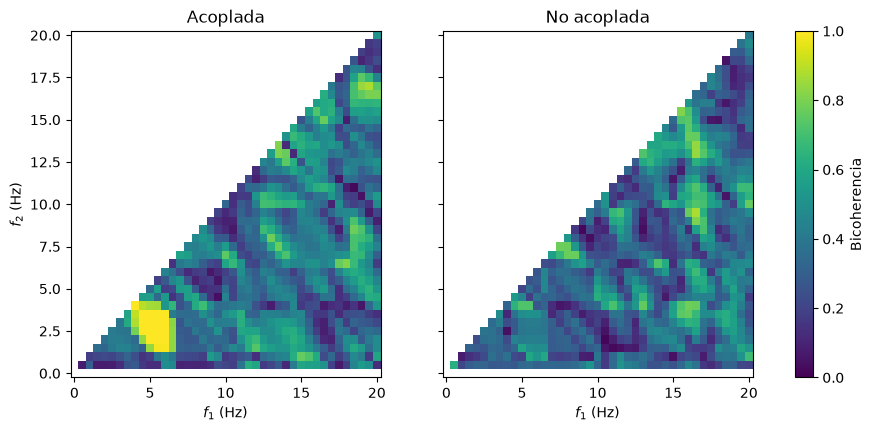

In [18]:
rng = np.random.default_rng(0)
t = np.arange(500) / FS

def sintetica(acoplada, n_seg=10):
    segs = []
    for _ in range(n_seg):
        p1, p2, p3 = rng.uniform(0, 2 * np.pi, 3)
        p3 = p1 + p2 if acoplada else p3
        segs.append(np.cos(2*np.pi*5*t + p1) + np.cos(2*np.pi*3*t + p2)
                    + np.cos(2*np.pi*8*t + p3) + 0.3 * rng.standard_normal(t.size))
    return np.concatenate(segs)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for eje, acoplada in zip(ejes, (True, False)):
    f, b, B, N, region = biespectro_bicoherencia(sintetica(acoplada), nfft=1000)
    i5, i3 = np.argmin(abs(f - 5)), np.argmin(abs(f - 3))
    print(f"{'Acoplada' if acoplada else 'No acoplada':12s} B(5,3) = {B[i5, i3]:.3f}   umbral = {umbral_bicoherencia(N):.3f}")
    im = eje.pcolormesh(f, f, np.where(region, B, np.nan).T, vmin=0, vmax=1, shading="auto")
    eje.set_title("Acoplada" if acoplada else "No acoplada")
    eje.set_xlabel("$f_1$ (Hz)")
ejes[0].set_ylabel("$f_2$ (Hz)")
fig.colorbar(im, ax=ejes, label="Bicoherencia")
plt.show()

In [19]:
rng_ruido = np.random.default_rng(1)
tasas = []
for _ in range(50):
    f, b, B, N, region = biespectro_bicoherencia(rng_ruido.standard_normal(5000))
    tasas.append((B[region] > umbral_bicoherencia(N)).mean())
print(f"Pares evaluados: {region.sum()}   Falsos positivos en ruido blanco: {100*np.mean(tasas):.1f} %"
      f"  (~{np.mean(tasas)*region.sum():.0f} pares por señal)")

Pares evaluados: 820   Falsos positivos en ruido blanco: 7.2 %  (~59 pares por señal)


## Aplicación a señales del subconjunto del punto 2

Se toma un registro al azar de cada ritmo del subconjunto y se aplica la cadena completa: curva $\delta(n)$ → *detrending* con el grado elegido → compresión → bicoherencia.

In [20]:
subconjunto = pd.read_csv(RUTA_SUBCONJUNTO)
print(subconjunto["Rhythm"].value_counts())

def procesar_registro(nombre, grados=range(0, 21)):
    x = cargar_ecg(RUTA_SENALES / f"{nombre}.csv")
    g, d = curva_delta(x, grados)
    n = elegir_grado(g, d)
    x_det, _ = detrend_polinomial(x, n)
    s = compresion(x_det)
    f, b, B, N, region = biespectro_bicoherencia(s)
    return dict(x=x, grados=g, deltas=d, n=n, s=s, f=f, b=b, B=B, N=N, region=region)

def primer_valido(grupo, semilla=42):
    for nombre in grupo.sample(frac=1, random_state=semilla)["FileName"]:
        try:
            return nombre, procesar_registro(nombre)
        except ValueError as e:
            print("  Se omite:", e)
    return None, None

resultados = {}
for ritmo, grupo in subconjunto.groupby("Rhythm"):
    nombre, r = primer_valido(grupo)
    if r is not None:
        resultados[ritmo] = r
        print(f"{ritmo}: {nombre}")

Rhythm
SB      3493
AFIB    1700
SR      1467
ST      1174
SVT      454
Name: count, dtype: int64
AFIB: MUSE_20180113_122043_40000
SB: MUSE_20180112_134027_79000
SR: MUSE_20180113_125854_77000
ST: MUSE_20180112_075431_42000
SVT: MUSE_20180712_151222_03000


In [21]:
"""cabe aclarar que si el archivo de algun 
paciente tiene valores faltantes o NaNel proceso se detiene"""
#ejemplo de un paciente que tenia valores faltantes 
ruta_mala = RUTA_SENALES / "MUSE_20181222_204131_50000.csv"
datos = pd.read_csv(ruta_mala, header=None).to_numpy(dtype=float)
print("Forma:", datos.shape)
print("NaN por derivación:", np.isnan(datos).sum(axis=0))
print("Rango por derivación:", np.round(np.nanmax(datos, axis=0) - np.nanmin(datos, axis=0), 2))

Forma: (5000, 12)
NaN por derivación: [0 0 0 0 0 0 0 0 0 0 0 0]
Rango por derivación: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


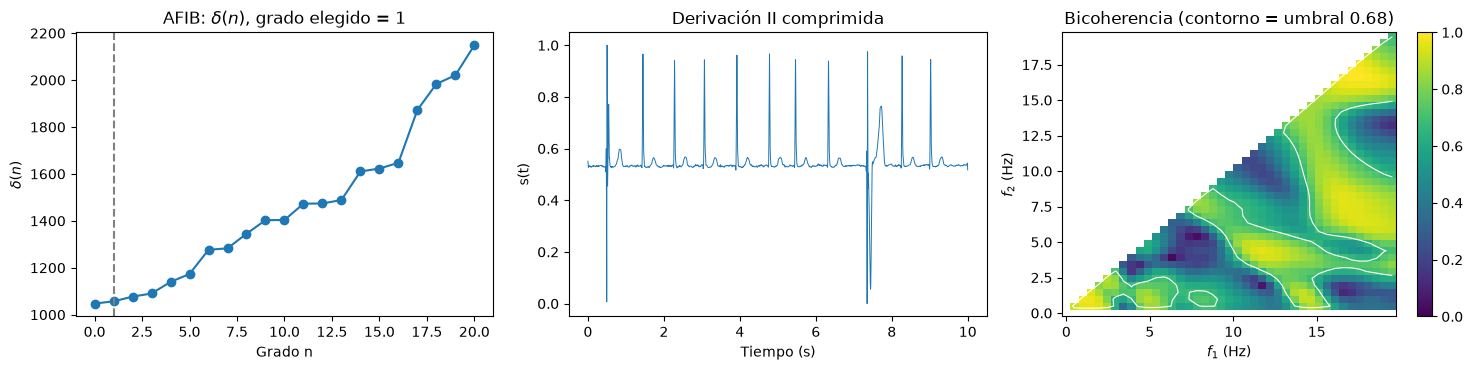

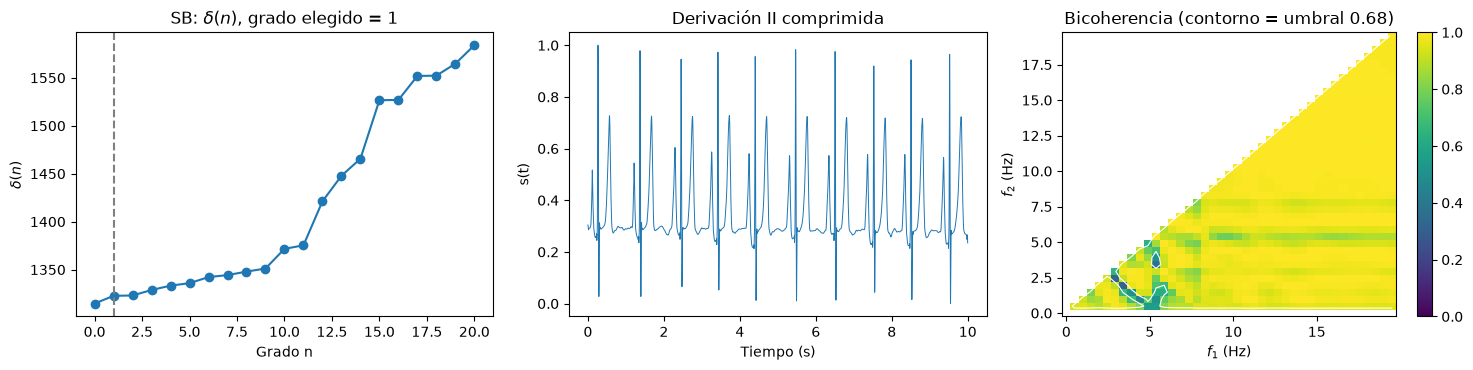

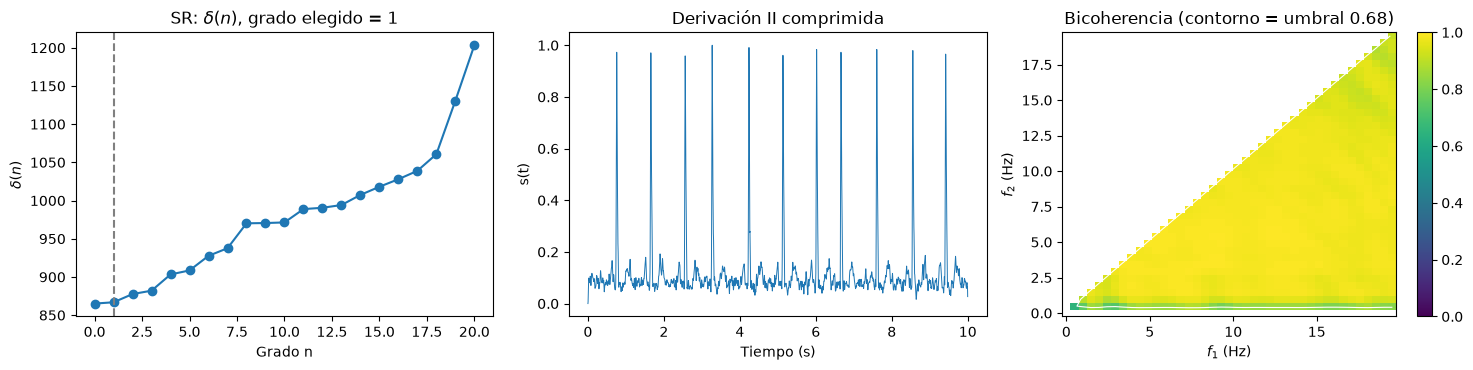

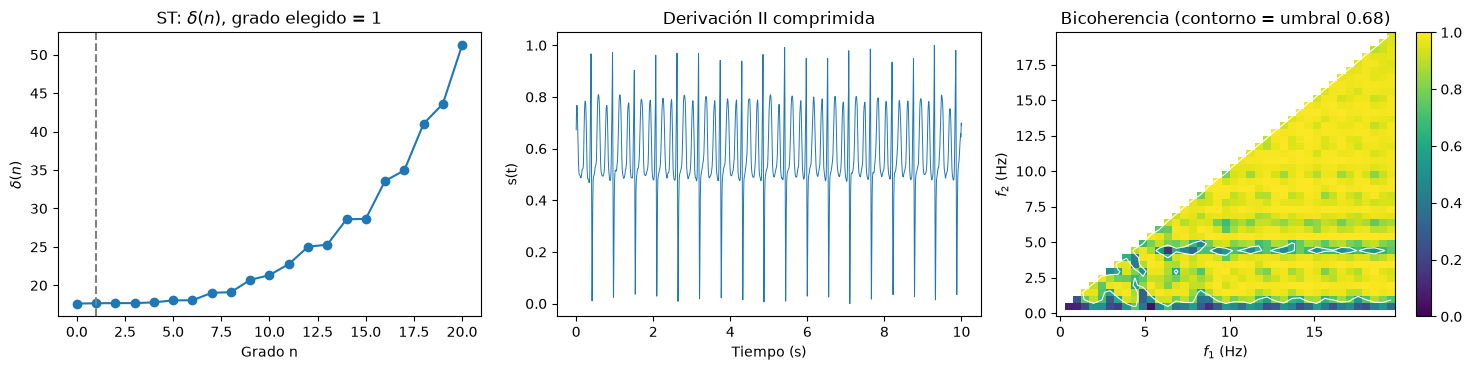

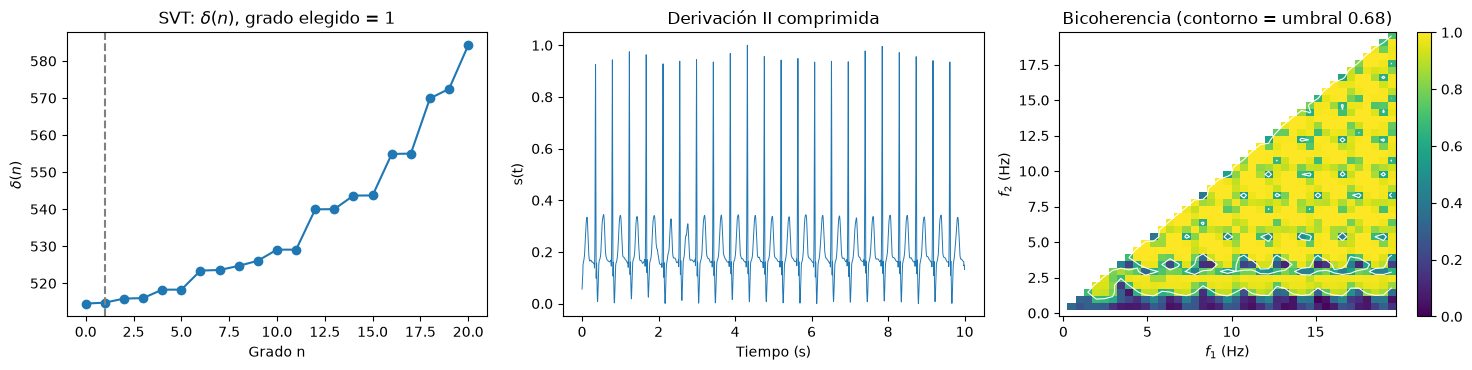

In [22]:
for ritmo, r in resultados.items():
    fig, ejes = plt.subplots(1, 3, figsize=(15, 3.8))
    ejes[0].plot(r["grados"], r["deltas"], "o-")
    ejes[0].axvline(r["n"], ls="--", c="gray")
    ejes[0].set(title=f"{ritmo}: $\\delta(n)$, grado elegido = {r['n']}", xlabel="Grado n", ylabel="$\\delta(n)$")
    tt = np.arange(r["s"].size) / FS
    ejes[1].plot(tt, r["s"], lw=0.7)
    ejes[1].set(title="Derivación II comprimida", xlabel="Tiempo (s)", ylabel="s(t)")
    u = umbral_bicoherencia(r["N"])
    im = ejes[2].pcolormesh(r["f"], r["f"], np.where(r["region"], r["B"], np.nan).T, vmin=0, vmax=1, shading="auto")
    ejes[2].contour(r["f"], r["f"], np.where(r["region"], r["B"], 0).T, levels=[u], colors="w", linewidths=0.8)
    ejes[2].set(title=f"Bicoherencia (contorno = umbral {u:.2f})", xlabel="$f_1$ (Hz)", ylabel="$f_2$ (Hz)")
    fig.colorbar(im, ax=ejes[2])
    plt.tight_layout()
    plt.show()

## Significado y utilidad del biespectro

**Qué es.** El espectro de potencia es la transformada de Fourier de la autocorrelación (estadística de segundo orden): dice cuánta energía hay en cada frecuencia, pero descarta las fases. El biespectro es la transformada de Fourier de la correlación de tercer orden, $E[x(t)\,x(t+\tau_1)\,x(t+\tau_2)]$, y es una función de dos frecuencias. Su valor en $(f_1, f_2)$ es grande cuando existe una componente en $f_1 + f_2$ cuya fase está ligada a las de $f_1$ y $f_2$ ($\varphi_3 = \varphi_1 + \varphi_2$) de forma consistente entre segmentos. Eso se llama acoplamiento cuadrático de fase.

**Por qué importa.** Un sistema lineal no crea frecuencias nuevas: si entran $f_1$ y $f_2$, salen $f_1$ y $f_2$. Un sistema no lineal (por ejemplo, con un término cuadrático) genera $f_1 + f_2$ y $f_1 - f_2$ con fases amarradas a las originales. Por tanto, el biespectro distingue dos señales que tienen el mismo espectro de potencia: una cuyos picos son armónicos generados por la misma dinámica y otra cuyos picos son componentes independientes o ruido. Además, para un proceso gaussiano el biespectro es cero, así que también mide desviación de la gaussianidad.

**Bicoherencia.** El biespectro depende de la amplitud de la señal; la bicoherencia lo normaliza entre 0 (fases sin relación) y 1 (acoplamiento perfecto), lo que permite comparar registros y aplicar un umbral de significancia.

**Utilidad en ECG.** El latido produce una frecuencia fundamental (frecuencia de pulso, cerca de 1 Hz) y armónicos generados por la forma no sinusoidal del complejo P-QRS-T. En un corazón sano esos armónicos están acoplados en fase con el pulso. Kotriwar et al. encontraron que en sujetos sanos el pulso tiene acoplamiento significativo con muchas frecuencias, mientras que en patologías ese acoplamiento se pierde o aparecen frecuencias de potencia alta sin acoplamiento, que sugieren ruido o procesos estocásticos. En arritmias como la fibrilación auricular, donde la activación auricular es desorganizada y los intervalos RR son irregulares, se espera una estructura de bicoherencia distinta a la del ritmo sinusal. Esa diferencia es la que se cuantifica en los puntos 5 a 8. Otras aplicaciones del análisis biespectral incluyen EEG (por ejemplo, el índice biespectral de profundidad anestésica), detección de fallas en maquinaria y análisis de oleaje.

---
## Punto 4. Frecuencia de máxima potencia (fMP)

**Qué se hace:**
1. Se toma la señal y se preprocesa con las **funciones del punto 3**, en este orden:
   - se elige el grado del polinomio con la curva δ(n);
   - se quita la tendencia;
   - se comprime la señal entre 0 y 1.
2. Se calcula el **espectro de potencia** con el método de Welch, que es el que usa el artículo. Se usan ventanas de 5 s, lo que da una resolución de 0,2 Hz.
3. La **fMP** es la frecuencia donde el espectro es más alto.


In [23]:
from scipy.signal import welch


def preprocesar(x):
    """Ecuaciones 1 y 2 usando las funciones del punto 3."""
    grados, deltas = curva_delta(x)
    n = elegir_grado(grados, deltas)
    x_sin_tendencia, _ = detrend_polinomial(x, n)
    return compresion(x_sin_tendencia)


def espectro_potencia(s, fs=FS):
    """Espectro de potencia por el método de Welch (ventanas de 5 s)."""
    f, P = welch(s - np.mean(s), fs=fs, nperseg=2500)
    return f, P


def calcular_fmp(s, fs=FS):
    """Frecuencia de máxima potencia: la frecuencia donde P es máximo."""
    f, P = espectro_potencia(s, fs)
    return f[np.argmax(P)]

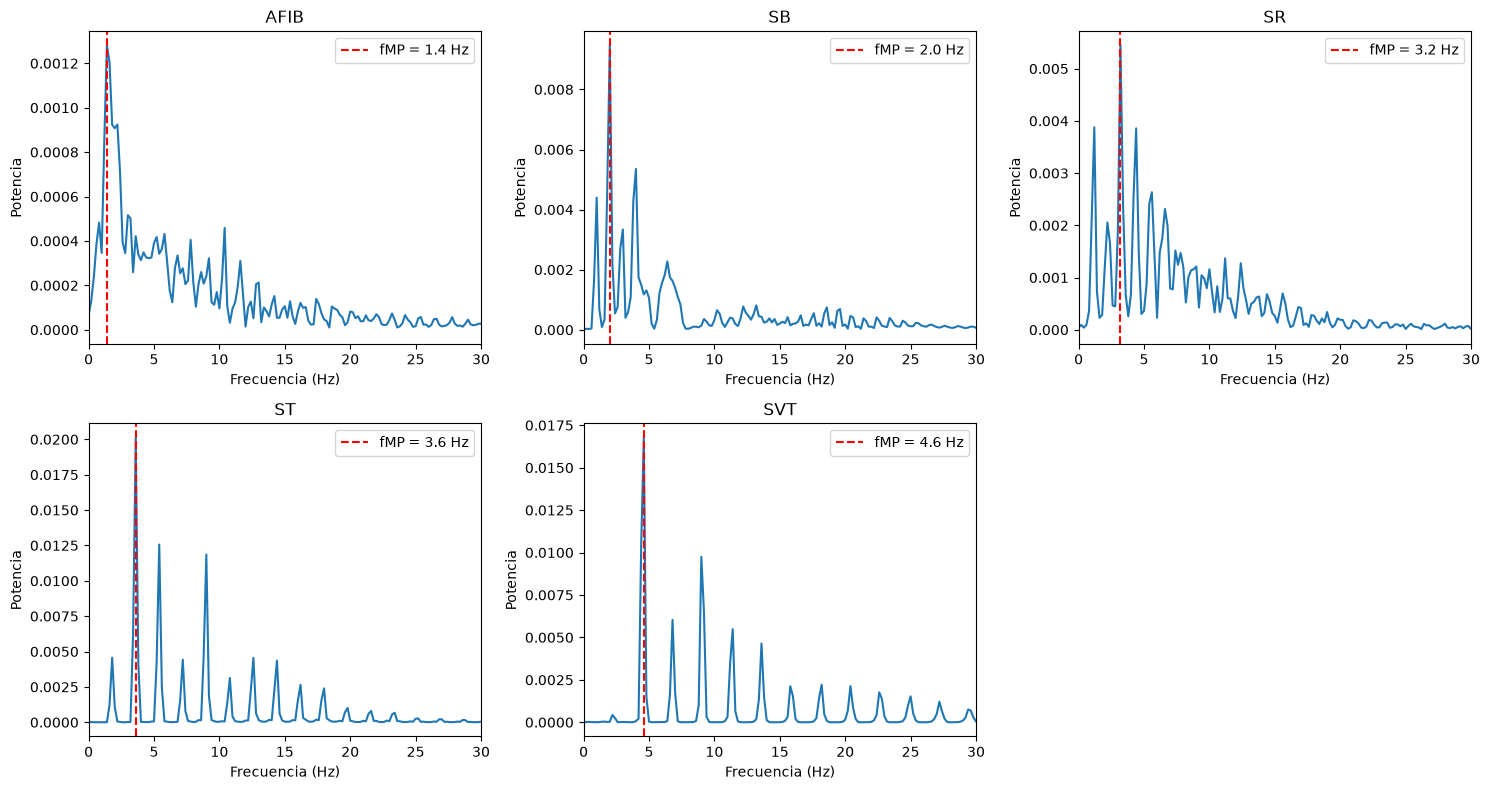

In [24]:
plt.figure(figsize=(15, 8))
i = 1
for ritmo in resultados:                  # 'resultados' es el diccionario del punto 3: un registro por ritmo
    s = resultados[ritmo]["s"]            # señal ya preprocesada en el punto 3
    f, P = espectro_potencia(s)
    fmp = calcular_fmp(s)

    plt.subplot(2, 3, i)
    plt.plot(f, P)
    plt.axvline(fmp, color="red", linestyle="--", label=f"fMP = {fmp:.1f} Hz")
    plt.xlim(0, 30)
    plt.title(ritmo)
    plt.xlabel("Frecuencia (Hz)")
    plt.ylabel("Potencia")
    plt.legend()
    i = i + 1
plt.tight_layout()
plt.show()

---
## Punto 5. Suma de frecuencias significativas en bicoherencia (sFSB)

**Qué se hace:**
1. Se usa la bicoherencia $B(f_1, f_2)$ que ya se calculó en el punto 3 para cada señal (ec. 4).
2. Se compara cada par de frecuencias con el umbral

$$B(f_1, f_2) > \sqrt{\frac{9.2}{2N}}$$

   donde $N$ es el número de segmentos (aquí $N = 10$, umbral $\approx 0.678$).
3. La **sFSB** es el número de pares $(f_1, f_2)$ que superan el umbral dentro de la región no redundante ($f_2 > 0$, $f_1 \ge f_2$, hasta 20 Hz). Son 820 pares posibles por señal.

**Cómo leer el resultado.** Un valor alto significa que muchas frecuencias del ECG tienen la fase acoplada entre sí, como se espera de un latido regular con armónicos bien definidos. Un valor bajo indica que las componentes de frecuencia varían de forma independiente.

**Piso de ruido.** Como se vio en el punto 3, con la normalización de la ec. (4) cerca de 7 % de los pares supera el umbral incluso en ruido blanco puro. Por eso se calcula también ese piso con los mismos parámetros, para saber qué parte de la sFSB se esperaría solo por azar.

In [25]:
def contar_significativas(B, region, N):
    """Número de pares (f1, f2) de la región no redundante con B mayor que el umbral."""
    umbral = umbral_bicoherencia(N)
    return int(np.sum(B[region] > umbral))


def calcular_sfsb(s, fs=FS):
    """sFSB de una señal ya preprocesada (detrending + compresión)."""
    f, b, B, N, region = biespectro_bicoherencia(s, fs)
    return contar_significativas(B, region, N)


def piso_ruido_sfsb(repeticiones=50, n_muestras=5000, semilla=1):
    """sFSB promedio de ruido blanco con los mismos parámetros: lo que se espera solo por azar."""
    rng = np.random.default_rng(semilla)
    valores = [calcular_sfsb(rng.standard_normal(n_muestras)) for _ in range(repeticiones)]
    return np.mean(valores), np.std(valores)

In [26]:
piso_media, piso_std = piso_ruido_sfsb()
print(f"Piso de ruido: sFSB = {piso_media:.0f} ± {piso_std:.0f} pares (de 820 posibles)\n")

filas = []
for ritmo in resultados:                  # 'resultados' es el diccionario del punto 3: un registro por ritmo
    r = resultados[ritmo]
    sfsb = contar_significativas(r["B"], r["region"], r["N"])
    fmp = calcular_fmp(r["s"])            # función del punto 4
    filas.append([ritmo, round(fmp, 2), sfsb, round(100 * sfsb / r["region"].sum(), 1)])

tabla_p5 = pd.DataFrame(filas, columns=["Ritmo", "fMP (Hz)", "sFSB", "% de pares significativos"])
tabla_p5

Piso de ruido: sFSB = 59 ± 23 pares (de 820 posibles)



,Ritmo,fMP (Hz),sFSB,% de pares significativos
0,AFIB,1.4,405,49.4
1,SB,2.0,805,98.2
2,SR,3.2,819,99.9
3,ST,3.6,732,89.3
4,SVT,4.6,645,78.7


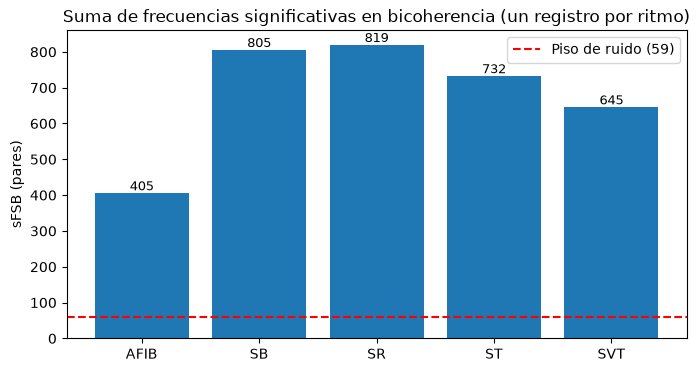

In [27]:
plt.figure(figsize=(8, 4))
plt.bar(tabla_p5["Ritmo"], tabla_p5["sFSB"])
for i in range(len(tabla_p5)):
    plt.text(i, tabla_p5["sFSB"][i], str(tabla_p5["sFSB"][i]), ha="center", va="bottom", fontsize=9)
plt.axhline(piso_media, color="red", linestyle="--", label=f"Piso de ruido ({piso_media:.0f})")
plt.title("Suma de frecuencias significativas en bicoherencia (un registro por ritmo)")
plt.ylabel("sFSB (pares)")
plt.legend()
plt.show()

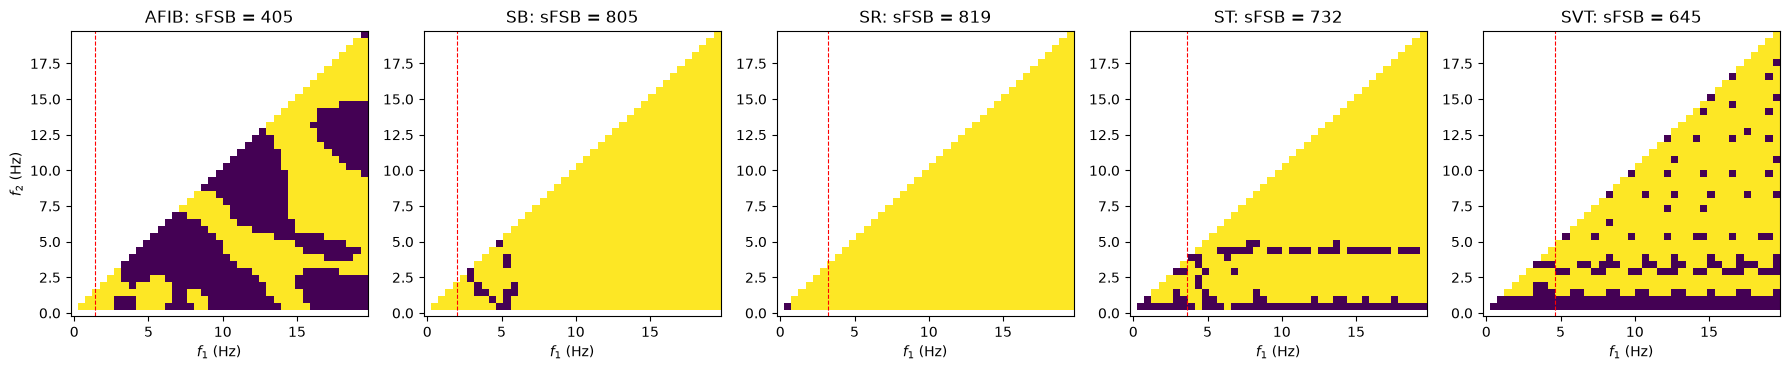

In [28]:
# Mapa de los pares significativos de cada ritmo (amarillo = supera el umbral)
plt.figure(figsize=(18, 3.8))
i = 1
for ritmo in resultados:
    r = resultados[ritmo]
    significativos = (r["B"] > umbral_bicoherencia(r["N"])) & r["region"]
    mapa = np.where(r["region"], significativos, np.nan)

    plt.subplot(1, len(resultados), i)
    plt.pcolormesh(r["f"], r["f"], mapa.T, vmin=0, vmax=1, shading="auto")
    fmp = calcular_fmp(r["s"])
    plt.axvline(fmp, color="red", linestyle="--", linewidth=0.8)
    plt.title(f"{ritmo}: sFSB = {significativos.sum()}")
    plt.xlabel("$f_1$ (Hz)")
    if i == 1:
        plt.ylabel("$f_2$ (Hz)")
    i = i + 1
plt.tight_layout()
plt.show()

La línea roja punteada marca la fMP del punto 4. Si el pulso está acoplado con sus armónicos, se esperan pares significativos alineados sobre esa columna y sus múltiplos.

**Nota.** Con un solo registro por ritmo esto es solo una ilustración. Para concluir si la sFSB cambia entre arritmias hacen falta muchos pacientes por grupo; eso se hace en los puntos 6 a 8, aplicando `calcular_sfsb` a todas las señales. (PENDIENTE DE ESTO MANU, QUE SI SE VEA REALMENTE SI HAY UN CAMBIO O SI NO CAMBIA)


---
## Punto 6. Rutina sobre todos los archivos de la base de datos

**Qué pide el enunciado:** aplicar a **todos** los registros de la base las rutinas de los puntos 3 a 5, y guardar los resultados en un dataframe con las columnas **Registro | Estado | fMP | sFSB**.

**Qué se hace:**
1. Se define la función `procesar_paciente`, que repite para **un** paciente lo que ya se hizo en los puntos 3, 4 y 5:

   | Paso | Función que se usa | Punto |
   |---|---|---|
   | Leer la derivación II | `cargar_ecg` | 3 |
   | Quitar la tendencia y comprimir (Ec. 1 y 2) | `preprocesar` | 3 y 4 |
   | Frecuencia de máxima potencia | `calcular_fmp` | 4 |
   | Suma de frecuencias significativas en bicoherencia | `calcular_sfsb` | 5 |

2. Un ciclo `for` recorre los 10.646 pacientes de `Diagnostics.xlsx` y llama a esa función para cada uno.
3. Cada resultado se guarda como una fila, y al final las filas se convierten en un dataframe.

No se crea ninguna fórmula nueva: este punto solo **reutiliza** las funciones de los puntos anteriores.


### 6.1 Función para un paciente
Algunos archivos no sirven:
- hay señales con **solo ceros**, como `MUSE_20181222_204131_50000`, que se mostró en el punto 3;
- hay registros **incompletos**, con menos de 5.000 muestras (10 s).

En esos casos la función devuelve `NaN` (valor vacío) en lugar de detener todo el proceso.


In [29]:
def procesar_paciente(nombre):
    """Aplica los puntos 3, 4 y 5 a un paciente. Devuelve (fMP, sFSB)."""
    try:
        x = cargar_ecg(RUTA_SENALES / f"{nombre}.csv")    # punto 3: leer la derivación II
    except (ValueError, FileNotFoundError):
        return np.nan, np.nan                            # señal vacía o archivo que no existe

    if len(x) != 5000:
        return np.nan, np.nan                            # registro incompleto (menos de 10 s)

    s = preprocesar(x)                                   # puntos 3 y 4: Ec. 1 y Ec. 2
    fmp = calcular_fmp(s)                                # punto 4
    sfsb = calcular_sfsb(s)                              # punto 5
    return fmp, sfsb

Prueba con un solo paciente, para comprobar que la función sirve antes de recorrer toda la base:

In [30]:
nombre = df["FileName"][0]
print("Paciente:", nombre, "| Ritmo:", df["Rhythm"][0])
fmp, sfsb = procesar_paciente(nombre)
print(f"fMP = {fmp:.2f} Hz   |   sFSB = {sfsb} pares")

Paciente: MUSE_20180113_171327_27000 | Ritmo: AFIB
fMP = 9.00 Hz   |   sFSB = 691 pares


### 6.2 Recorrer toda la base de datos
El ciclo `for` va paciente por paciente:
1. toma el nombre del archivo (`FileName`) y el ritmo (`Rhythm`);
2. llama a `procesar_paciente`;
3. guarda una fila con los 4 datos.

Cada 1.000 pacientes imprime el avance, porque el proceso completo tarda varios minutos. Al final, las filas se convierten en un dataframe y se guardan en `resultados_punto6.csv` para usarlas en los puntos 7 y 8.


In [31]:
filas_p6 = []

for i in range(len(df)):
    registro = df["FileName"][i]
    estado = df["Rhythm"][i]

    fmp, sfsb = procesar_paciente(registro)
    filas_p6.append([registro, estado, fmp, sfsb])

    if (i + 1) % 1000 == 0:
        print(i + 1, "de", len(df), "pacientes procesados")

tabla_resultados = pd.DataFrame(filas_p6, columns=["Registro", "Estado", "fMP", "sFSB"])
tabla_resultados.to_csv("resultados_punto6.csv", index=False)
print("Terminado")

1000 de 10646 pacientes procesados
2000 de 10646 pacientes procesados
3000 de 10646 pacientes procesados
4000 de 10646 pacientes procesados
5000 de 10646 pacientes procesados
6000 de 10646 pacientes procesados
7000 de 10646 pacientes procesados
8000 de 10646 pacientes procesados
9000 de 10646 pacientes procesados
10000 de 10646 pacientes procesados
Terminado


### 6.3 Resultado: dataframe Registro | Estado | fMP | sFSB

In [32]:
print("Pacientes en la tabla:", len(tabla_resultados))
print("Pacientes con resultado:", tabla_resultados["fMP"].notna().sum())
print("Pacientes sin resultado (señal vacía o incompleta):", tabla_resultados["fMP"].isna().sum())

tabla_resultados.head(10)

Pacientes en la tabla: 10646
Pacientes con resultado: 10605
Pacientes sin resultado (señal vacía o incompleta): 41


,Registro,Estado,fMP,sFSB
0,MUSE_20180113_171327_27000,AFIB,9.0,691.0
1,MUSE_20180112_073319_29000,SB,3.4,818.0
2,MUSE_20180111_165520_97000,SA,1.2,798.0
3,MUSE_20180113_121940_44000,SB,3.6,818.0
4,MUSE_20180112_122850_57000,AF,5.4,623.0
5,MUSE_20180112_120347_79000,SB,3.8,818.0
6,MUSE_20180114_075026_69000,AFIB,4.0,696.0
7,MUSE_20180209_172046_21000,SR,1.0,781.0
8,MUSE_20180114_075128_92000,SB,1.0,818.0
9,MUSE_20180118_174026_42000,SB,3.0,817.0


Pacientes que quedaron sin resultado:

In [33]:
sin_resultado = tabla_resultados[tabla_resultados["fMP"].isna()]
sin_resultado

,Registro,Estado,fMP,sFSB
1789,MUSE_20180113_124215_52000,SB,NaN,NaN
10606,MUSE_20181222_204118_08000,SVT,NaN,NaN
10607,MUSE_20181222_204121_42000,SVT,NaN,NaN
10608,MUSE_20181222_204122_52000,SVT,NaN,NaN
10609,MUSE_20181222_204123_64000,SVT,NaN,NaN
10610,MUSE_20181222_204128_13000,SVT,NaN,NaN
10611,MUSE_20181222_204131_50000,SVT,NaN,NaN
10612,MUSE_20181222_204132_64000,SVT,NaN,NaN
10613,MUSE_20181222_204140_77000,SVT,NaN,NaN
10614,MUSE_20181222_204141_91000,SVT,NaN,NaN


**Resumen del punto 6.**
- La tabla `tabla_resultados` tiene un renglón por paciente, con su registro, su ritmo (estado), su fMP y su sFSB.
- Esta tabla es la que se usa en el **punto 7**, para la estadística descriptiva, y en el **punto 8**, para las pruebas estadísticas. En ambos se filtra con el subconjunto del punto 2.


---
## Punto 7. Diferencias entre arritmias con estadística descriptiva

**Qué pide el enunciado:** aplicar las rutinas de los puntos 3 a 5 a las señales del subconjunto del punto 2 y mostrar, con estadística descriptiva, las diferencias entre las arritmias.

**Qué se hace:**
1. Se toma la tabla del punto 6 (`tabla_resultados`) y se dejan solo los pacientes del subconjunto del punto 2: cinco ritmos, de 40 a 89 años. No se vuelve a procesar ninguna señal.
2. Para la fMP y la sFSB se calcula, por ritmo: media, desviación estándar, mediana, cuartiles, rango intercuartílico (RIC), mínimo, máximo y coeficiente de variación (CV).
3. Se grafican diagramas de cajas e histogramas por ritmo.
4. Se revisa qué representa la fMP en cada ritmo, comparándola con la frecuencia cardíaca del paciente.
5. Se repite la descripción solo con pacientes sin condiciones adicionales (`Beat == NONE`).

Los ritmos se ordenan de menor a mayor frecuencia cardíaca: SB, SR, ST, SVT y, al final, AFIB, que es irregular.

### 7.1 Datos del subconjunto
Si el kernel se reinició y no se quiere repetir el punto 6 (tarda varios minutos), la tabla se carga desde `resultados_punto6.csv`.

In [34]:
if "tabla_resultados" not in globals():
    tabla_resultados = pd.read_csv("resultados_punto6.csv")
    print("Tabla del punto 6 cargada desde resultados_punto6.csv")

orden_ritmos = ["SB", "SR", "ST", "SVT", "AFIB"]

# Se unen los resultados del punto 6 con los datos clínicos del subconjunto del punto 2
datos_p7 = tabla_resultados.merge(
    subconjunto[["FileName", "Beat", "PatientAge", "Gender", "VentricularRate"]],
    left_on="Registro", right_on="FileName")

print("Pacientes del subconjunto:", len(datos_p7))
sin_dato = datos_p7[datos_p7["fMP"].isna()]
print("Pacientes sin resultado (señal vacía o incompleta):", len(sin_dato))
print(sin_dato["Estado"].value_counts().reindex(orden_ritmos, fill_value=0))

datos_p7 = datos_p7[datos_p7["fMP"].notna()].copy()
print("\nPacientes que se usan en el punto 7:", len(datos_p7))
print(datos_p7["Estado"].value_counts().reindex(orden_ritmos))

Pacientes del subconjunto: 8288
Pacientes sin resultado (señal vacía o incompleta): 28
Estado
SB       1
SR       0
ST       0
SVT     27
AFIB     0
Name: count, dtype: int64

Pacientes que se usan en el punto 7: 8260
Estado
SB      3492
SR      1467
ST      1174
SVT      427
AFIB    1700
Name: count, dtype: int64


### 7.2 Tablas de estadística descriptiva

- **Media y mediana:** valor típico de cada ritmo. Si son muy distintas entre sí, la distribución es asimétrica y conviene mirar la mediana.
- **Desviación estándar y RIC:** qué tan dispersos están los pacientes dentro de un mismo ritmo.
- **CV:** la dispersión relativa a la media, en %. Permite comparar la variabilidad de ritmos con medias distintas.

In [35]:
def descriptiva(datos, variable):
    """Estadística descriptiva de una variable para cada ritmo."""
    tabla = datos.groupby("Estado")[variable].agg(
        n="count", media="mean", desv="std", mediana="median",
        Q1=lambda v: v.quantile(0.25), Q3=lambda v: v.quantile(0.75),
        minimo="min", maximo="max")
    tabla["RIC"] = tabla["Q3"] - tabla["Q1"]
    tabla["CV (%)"] = 100 * tabla["desv"] / tabla["media"]
    return tabla.reindex(orden_ritmos).round(2)


tabla_fmp = descriptiva(datos_p7, "fMP")
tabla_sfsb = descriptiva(datos_p7, "sFSB")

print("Frecuencia de máxima potencia, fMP (Hz):")
display(tabla_fmp)
print("\nSuma de frecuencias significativas en bicoherencia, sFSB (pares):")
display(tabla_sfsb)

Frecuencia de máxima potencia, fMP (Hz):


,n,media,desv,mediana,Q1,Q3,minimo,maximo,RIC,CV (%)
Estado,,,,,,,,,,
SB,3492,2.93,2.24,2.8,1.0,3.8,0.4,50.0,2.8,76.42
SR,1467,4.05,1.77,3.8,3.0,4.6,0.6,16.0,1.6,43.57
ST,1174,5.30,2.60,5.2,3.6,6.4,0.6,50.0,2.8,49.01
SVT,427,4.75,2.99,4.8,3.0,5.6,0.6,50.0,2.6,62.83
AFIB,1700,4.05,3.06,3.4,2.4,4.6,0.6,50.0,2.2,75.62



Suma de frecuencias significativas en bicoherencia, sFSB (pares):


,n,media,desv,mediana,Q1,Q3,minimo,maximo,RIC,CV (%)
Estado,,,,,,,,,,
SB,3492,783.06,49.81,800.0,768.0,816.0,228.0,820.0,48.0,6.36
SR,1467,771.16,50.74,782.0,750.0,808.0,391.0,820.0,58.0,6.58
ST,1174,731.46,66.66,753.0,709.0,774.0,246.0,820.0,65.0,9.11
SVT,427,629.91,72.85,628.0,573.5,685.0,350.0,788.0,111.5,11.57
AFIB,1700,741.84,93.17,771.0,717.0,803.0,72.0,820.0,86.0,12.56


### 7.3 Diagramas de cajas e histogramas
La caja va del primer al tercer cuartil y la línea del medio es la mediana. En la sFSB la línea roja es el piso de ruido del punto 5: lo que se esperaría solo por azar.

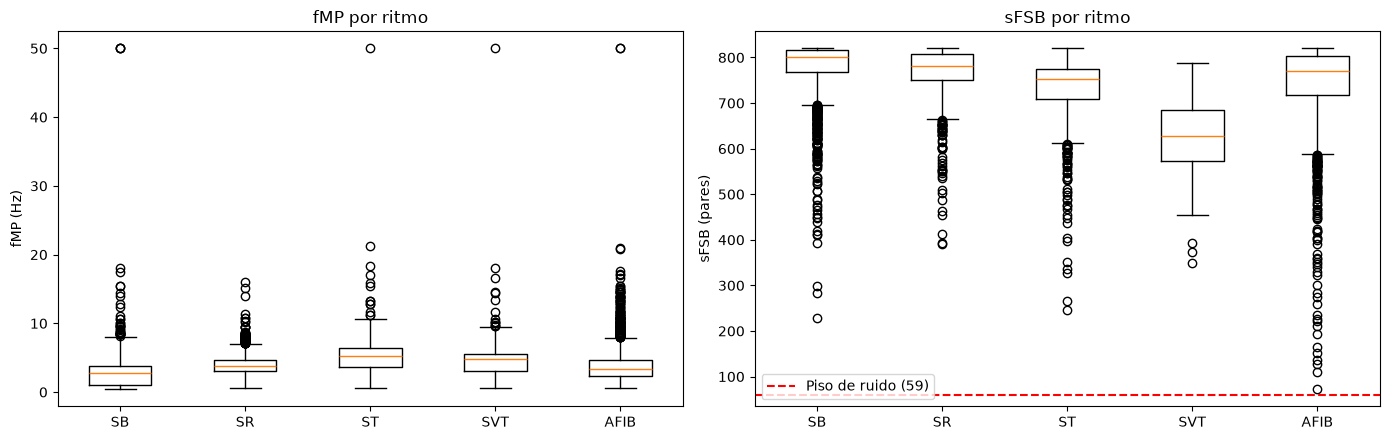

In [36]:
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))

ejes[0].boxplot([datos_p7[datos_p7["Estado"] == r]["fMP"] for r in orden_ritmos])
ejes[0].set_xticks(range(1, len(orden_ritmos) + 1), orden_ritmos)
ejes[0].set(title="fMP por ritmo", ylabel="fMP (Hz)")

ejes[1].boxplot([datos_p7[datos_p7["Estado"] == r]["sFSB"] for r in orden_ritmos])
ejes[1].set_xticks(range(1, len(orden_ritmos) + 1), orden_ritmos)
ejes[1].axhline(piso_media, color="red", linestyle="--", label=f"Piso de ruido ({piso_media:.0f})")
ejes[1].set(title="sFSB por ritmo", ylabel="sFSB (pares)")
ejes[1].legend()

plt.tight_layout()
plt.show()

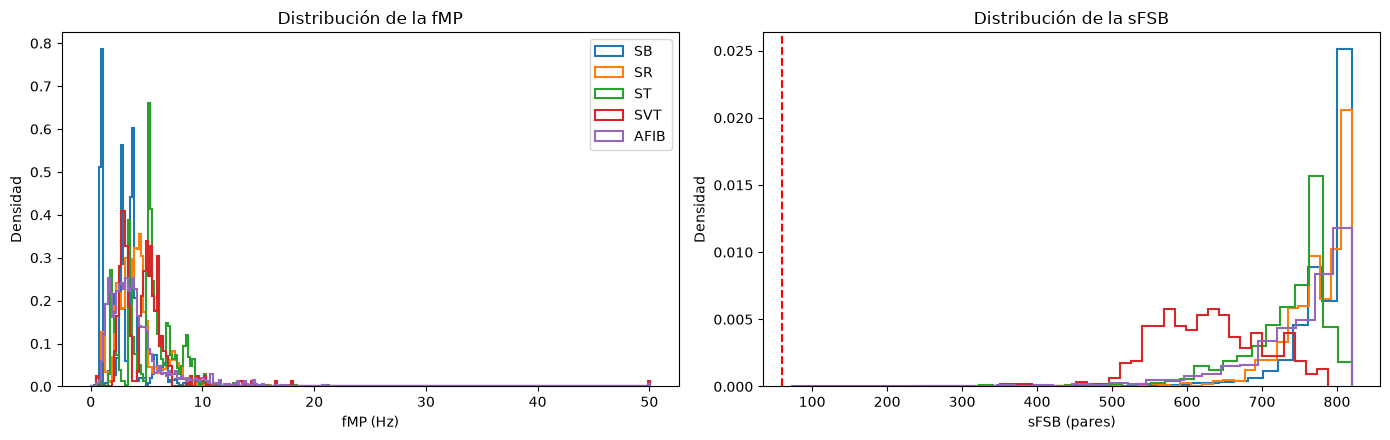

In [37]:
# La fMP solo toma múltiplos de 0,2 Hz (resolución de Welch con ventanas de 5 s), por eso los bordes van de 0,2 en 0,2
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.5))
bordes_fmp = np.arange(-0.1, datos_p7["fMP"].max() + 0.3, 0.2)
for ritmo in orden_ritmos:
    d = datos_p7[datos_p7["Estado"] == ritmo]
    ejes[0].hist(d["fMP"], bins=bordes_fmp, density=True, histtype="step", linewidth=1.5, label=ritmo)
    ejes[1].hist(d["sFSB"], bins=30, density=True, histtype="step", linewidth=1.5, label=ritmo)
ejes[0].set(title="Distribución de la fMP", xlabel="fMP (Hz)", ylabel="Densidad")
ejes[1].axvline(piso_media, color="red", linestyle="--")
ejes[1].set(title="Distribución de la sFSB", xlabel="sFSB (pares)", ylabel="Densidad")
ejes[0].legend()
plt.tight_layout()
plt.show()

### 7.4 ¿Qué representa la fMP en cada ritmo?

En el punto 5 la fMP del paciente SR salió en 3,2 Hz, mucho más alta que una frecuencia cardíaca normal (cerca de 1 Hz). Esto pasa porque la potencia del ECG no siempre se concentra en la frecuencia del latido: también puede estar en un **armónico** (2 o 3 veces esa frecuencia) o en la banda del complejo QRS.

Se compara la fMP con la frecuencia cardíaca de cada paciente, $f_c = \text{VentricularRate}/60$, y cada registro se clasifica como:
- **Fundamental:** la fMP está a menos de 0,2 Hz de $f_c$;
- **Armónico:** la fMP está a menos de 0,2 Hz de $2f_c$ o de $3f_c$;
- **Otra:** ninguna de las anteriores.

Así se sabe si una diferencia de fMP entre ritmos refleja la frecuencia cardíaca o la forma del latido.

Porcentaje de pacientes según qué representa la fMP:


Tipo fMP,Armónico,Fundamental,Otra
Estado,,,
SB,31.2,26.3,42.5
SR,60.1,5.9,34.0
ST,61.7,13.5,24.8
SVT,55.5,39.8,4.7
AFIB,15.0,18.8,66.2


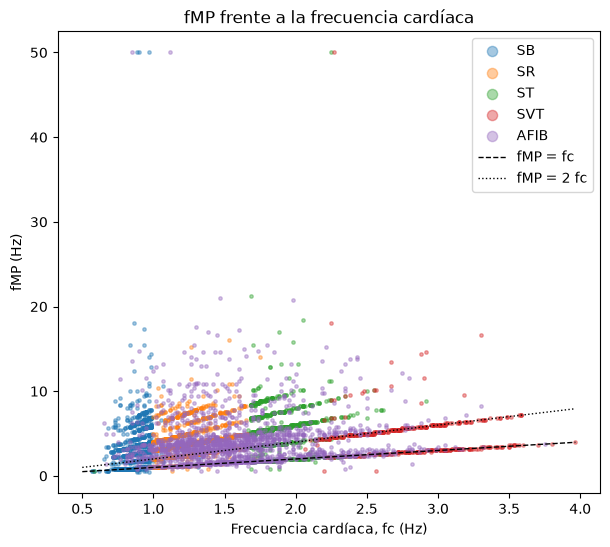

In [38]:
def tipo_de_fmp(fmp, fc, tolerancia=0.2):
    """Clasifica la fMP según su relación con la frecuencia cardíaca fc."""
    if abs(fmp - fc) <= tolerancia:
        return "Fundamental"
    if abs(fmp - 2 * fc) <= tolerancia or abs(fmp - 3 * fc) <= tolerancia:
        return "Armónico"
    return "Otra"


datos_p7["fc (Hz)"] = datos_p7["VentricularRate"] / 60
datos_p7["Tipo fMP"] = [tipo_de_fmp(a, b) for a, b in zip(datos_p7["fMP"], datos_p7["fc (Hz)"])]

tabla_tipo = 100 * pd.crosstab(datos_p7["Estado"], datos_p7["Tipo fMP"], normalize="index").reindex(orden_ritmos)
print("Porcentaje de pacientes según qué representa la fMP:")
display(tabla_tipo.round(1))

plt.figure(figsize=(7, 6))
for ritmo in orden_ritmos:
    d = datos_p7[datos_p7["Estado"] == ritmo]
    plt.scatter(d["fc (Hz)"], d["fMP"], s=6, alpha=0.4, label=ritmo)
eje_fc = np.linspace(0.5, datos_p7["fc (Hz)"].max(), 50)
plt.plot(eje_fc, eje_fc, "k--", linewidth=1, label="fMP = fc")
plt.plot(eje_fc, 2 * eje_fc, "k:", linewidth=1, label="fMP = 2 fc")
plt.xlabel("Frecuencia cardíaca, fc (Hz)")
plt.ylabel("fMP (Hz)")
plt.title("fMP frente a la frecuencia cardíaca")
plt.legend(markerscale=3)
plt.show()

### 7.5 Relación entre fMP y sFSB

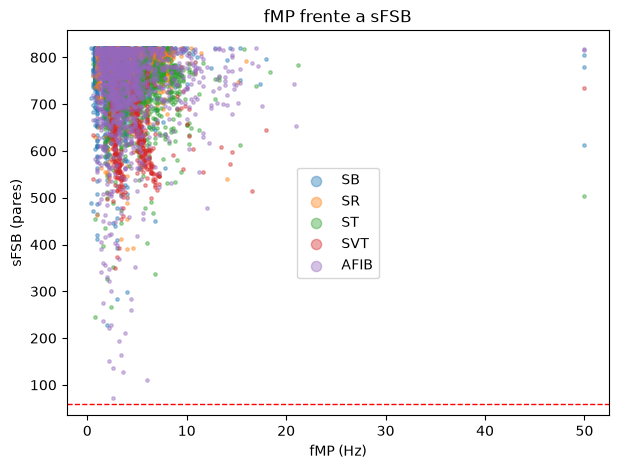

Porcentaje de pacientes con sFSB por encima del piso de ruido:
Estado
SB      100.0
SR      100.0
ST      100.0
SVT     100.0
AFIB    100.0
Name: sFSB, dtype: float64


In [39]:
plt.figure(figsize=(7, 5))
for ritmo in orden_ritmos:
    d = datos_p7[datos_p7["Estado"] == ritmo]
    plt.scatter(d["fMP"], d["sFSB"], s=6, alpha=0.4, label=ritmo)
plt.axhline(piso_media, color="red", linestyle="--", linewidth=1)
plt.xlabel("fMP (Hz)")
plt.ylabel("sFSB (pares)")
plt.title("fMP frente a sFSB")
plt.legend(markerscale=3)
plt.show()

print("Porcentaje de pacientes con sFSB por encima del piso de ruido:")
print((100 * datos_p7.groupby("Estado")["sFSB"].apply(lambda v: (v > piso_media).mean())).reindex(orden_ritmos).round(1))

### 7.6 Solo pacientes sin condiciones adicionales (`Beat == NONE`)
Bloqueos de rama, extrasístoles o hipertrofia cambian la forma del latido y, con ella, el espectro. Si las diferencias entre ritmos se mantienen sin esos pacientes, se deben al ritmo y no a esas condiciones.

In [40]:
datos_none = datos_p7[datos_p7["Beat"] == "NONE"]
print("Pacientes sin condiciones adicionales:", len(datos_none))
print("\nfMP (Hz):")
display(descriptiva(datos_none, "fMP")[["n", "media", "desv", "mediana", "RIC"]])
print("\nsFSB (pares):")
display(descriptiva(datos_none, "sFSB")[["n", "media", "desv", "mediana", "RIC"]])

Pacientes sin condiciones adicionales: 4048

fMP (Hz):


,n,media,desv,mediana,RIC
Estado,,,,,
SB,1912,2.70,1.46,2.8,2.80
SR,1056,3.99,1.54,3.8,1.60
ST,408,5.48,2.01,5.2,1.25
SVT,268,5.06,3.31,5.0,2.20
AFIB,404,4.13,2.07,3.8,1.40



sFSB (pares):


,n,media,desv,mediana,RIC
Estado,,,,,
SB,1912,782.52,45.11,793.0,47.00
SR,1056,769.30,47.76,777.0,59.00
ST,408,734.48,52.00,750.0,59.00
SVT,268,630.36,68.72,631.0,103.25
AFIB,404,746.81,68.60,764.0,88.25


---
## Punto 8. ¿Hay diferencias estadísticas en las características espectrales?

**Qué pide el enunciado:** indicar si hay o no diferencias estadísticas en las características espectrales de los puntos 4 (**fMP**) y 5 (**sFSB**) entre las poblaciones de estudio.

**Datos:** se usa la tabla `datos_p7` del punto 7. Tiene los pacientes del subconjunto del punto 2 (40–89 años; SB, SR, ST, SVT y AFIB) con su fMP y su sFSB del punto 6.

**Pasos:**
1. **Normalidad:** se revisa si los datos tienen forma de campana (distribución normal). De eso depende qué prueba usar.
2. **Comparación de todos los ritmos a la vez:** prueba de **Kruskal-Wallis**.
3. **Comparación de los ritmos de a dos:** prueba de **Mann-Whitney U**, para saber *cuáles* ritmos son distintos.

**Regla de decisión en todas las pruebas:**
- **p < 0,05:** sí hay diferencia estadísticamente significativa.
- **p ≥ 0,05:** no hay evidencia de diferencia.


### 8.1 ¿Los datos tienen distribución normal?
Se usa la prueba de normalidad de **D'Agostino-Pearson** (`stats.normaltest`):
- **p > 0,05:** los datos se pueden considerar normales;
- **p ≤ 0,05:** los datos **no** son normales.

Si los datos no son normales, no se pueden usar pruebas que comparan medias, como ANOVA o la prueba t. En su lugar se usan pruebas **no paramétricas**, que comparan las distribuciones (las medianas) sin suponer una forma de campana.


In [ ]:
def es_normal(valores):
    """Devuelve el p-valor de la prueba de normalidad y si los datos son normales (p > 0.05)."""
    estadistico, p = stats.normaltest(valores)
    return p, p > 0.05


filas_normal = []
for variable in ["fMP", "sFSB"]:
    for ritmo in orden_ritmos:
        valores = datos_p7[datos_p7["Estado"] == ritmo][variable]
        p, normal = es_normal(valores)
        filas_normal.append([variable, ritmo, p, normal])

tabla_normal = pd.DataFrame(filas_normal, columns=["Variable", "Ritmo", "p-valor", "¿Normal?"])
tabla_normal

### 8.2 Comparación de todos los ritmos a la vez (Kruskal-Wallis)
**Pregunta que responde:** ¿al menos un ritmo tiene una fMP (o una sFSB) distinta a la de los demás?

Es la versión no paramétrica del ANOVA: ordena todos los valores de menor a mayor y compara si los rangos de cada ritmo son parecidos.


In [ ]:
def comparar_todos(datos, variable):
    """Kruskal-Wallis entre todos los ritmos. Devuelve el estadístico H y el p-valor."""
    grupos = []
    for ritmo in orden_ritmos:
        grupos.append(datos[datos["Estado"] == ritmo][variable])
    H, p = stats.kruskal(*grupos)
    return H, p


for variable in ["fMP", "sFSB"]:
    H, p = comparar_todos(datos_p7, variable)
    if p < 0.05:
        print(f"{variable}: H = {H:.1f}, p = {p:.2e}  ->  SÍ hay diferencias entre los ritmos")
    else:
        print(f"{variable}: H = {H:.1f}, p = {p:.2e}  ->  NO hay diferencias entre los ritmos")

### 8.3 Comparación de los ritmos de a dos (Mann-Whitney U)
Kruskal-Wallis solo dice si *hay* alguna diferencia, no entre cuáles ritmos. Para saberlo se compara cada pareja de ritmos con la prueba de **Mann-Whitney U**. Con 5 ritmos hay 10 parejas.

**Corrección de Bonferroni:** al hacer 10 pruebas, aumenta la probabilidad de encontrar una diferencia solo por azar. Para compensar, cada p-valor se multiplica por el número de comparaciones (10). Si el resultado pasa de 1, se deja en 1.


In [ ]:
def comparar_dos(datos, variable, ritmo1, ritmo2, n_comparaciones):
    """Mann-Whitney U entre dos ritmos. Devuelve el p-valor corregido por Bonferroni."""
    grupo1 = datos[datos["Estado"] == ritmo1][variable]
    grupo2 = datos[datos["Estado"] == ritmo2][variable]
    estadistico, p = stats.mannwhitneyu(grupo1, grupo2)
    p_corregido = min(p * n_comparaciones, 1)
    return p_corregido


def tabla_parejas(datos, variable):
    """Compara todas las parejas de ritmos para una variable."""
    n_comparaciones = 10                     # 5 ritmos -> 10 parejas
    filas = []
    for i in range(len(orden_ritmos)):
        for j in range(i + 1, len(orden_ritmos)):
            ritmo1 = orden_ritmos[i]
            ritmo2 = orden_ritmos[j]
            mediana1 = datos[datos["Estado"] == ritmo1][variable].median()
            mediana2 = datos[datos["Estado"] == ritmo2][variable].median()
            p = comparar_dos(datos, variable, ritmo1, ritmo2, n_comparaciones)
            if p < 0.05:
                conclusion = "Sí"
            else:
                conclusion = "No"
            filas.append([ritmo1 + " vs " + ritmo2, mediana1, mediana2, p, conclusion])
    return pd.DataFrame(filas, columns=["Comparación", "Mediana 1", "Mediana 2",
                                        "p (Bonferroni)", "¿Diferencia significativa?"])

In [ ]:
print("Frecuencia de máxima potencia, fMP (Hz):")
parejas_fmp = tabla_parejas(datos_p7, "fMP")
parejas_fmp

In [ ]:
print("Suma de frecuencias significativas en bicoherencia, sFSB (pares):")
parejas_sfsb = tabla_parejas(datos_p7, "sFSB")
parejas_sfsb

### 8.4 Conclusión del punto 8
*(Se completa con los resultados obtenidos al ejecutar el notebook.)*